In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, roc_curve, auc, recall_score
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as imbpipeline

# Görselleştirme ayarları
%matplotlib inline
sns.set(style="whitegrid")

In [5]:
# Veriyi yükle
df = pd.read_csv('customer_churn_data.csv')

df['EstimatedTenure'] = df['TotalCharges'] / (df['MonthlyCharges'] + 0.1)
df['AvgMonthlySpend'] = df['TotalCharges'] / (df['tenure'] + 1)
df['IsHighValue'] = (df['MonthlyCharges'] > df['MonthlyCharges'].mean()).astype(int)
df['Charges_Ratio'] = df['MonthlyCharges'] / (df['TotalCharges'] + 1)
df = df.drop('customerID', axis=1)
df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})
df = pd.get_dummies(df, drop_first=True)

In [6]:
X = df.drop('Churn', axis=1)
y = df['Churn']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

# Baseline: Hiçbir şey bilmeyen modelin başarısı
dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X_train, y_train)
dummy_acc = dummy.score(X_test, y_test)
print(f"Baseline (Yazı-Tura) Başarı Oranı: {dummy_acc:.4f}")

Baseline (Yazı-Tura) Başarı Oranı: 0.4966


In [7]:
# Random Forest Pipeline (Scaling + SMOTE + Model)
rf_pipe = imbpipeline(steps=[
    ('scaler', StandardScaler()),
    ('smote', SMOTE(random_state=42)),
    ('classifier', RandomForestClassifier(random_state=42, class_weight='balanced'))
])

# GridSearchCV: scoring='recall' yaparak kaçacak müşteriyi yakalamaya odaklanıyoruz
rf_params = {'classifier__n_estimators': [200], 'classifier__max_depth': [20]}
grid_rf = GridSearchCV(rf_pipe, rf_params, cv=5, scoring='recall')
grid_rf.fit(X_train, y_train)

best_model = grid_rf.best_estimator_

# Diğer modeller (Kıyaslama için hızlı eğitim)
log_pipe = imbpipeline(steps=[('scaler', StandardScaler()), ('smote', SMOTE(random_state=42)),
                              ('classifier', LogisticRegression(class_weight='balanced'))]).fit(X_train, y_train)

xgb_pipe = imbpipeline(steps=[('scaler', StandardScaler()), ('smote', SMOTE(random_state=42)),
                              ('classifier', XGBClassifier(eval_metric='logloss'))]).fit(X_train, y_train)

In [8]:
models = [('Baseline', dummy), ('Lojistik Reg.', log_pipe), ('XGBoost', xgb_pipe), ('Random Forest', best_model)]
results = []
for name, model in models:
    preds = model.predict(X_test)
    results.append({'Model': name, 'Accuracy': accuracy_score(y_test, preds), 'Recall': recall_score(y_test, preds)})

model_results_df = pd.DataFrame(results)
print(model_results_df)

           Model  Accuracy    Recall
0       Baseline  0.496599  0.000000
1  Lojistik Reg.  0.489796  0.518581
2        XGBoost  0.503401  0.500000
3  Random Forest  0.475340  0.476351


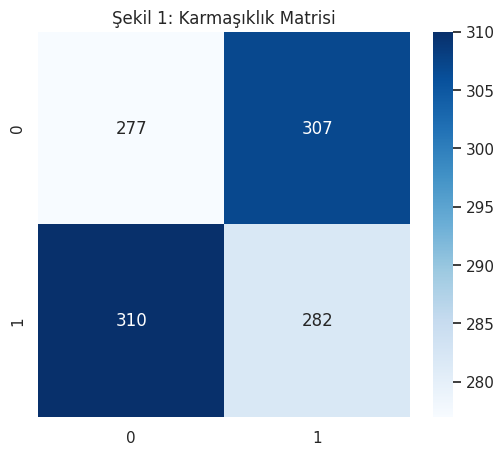

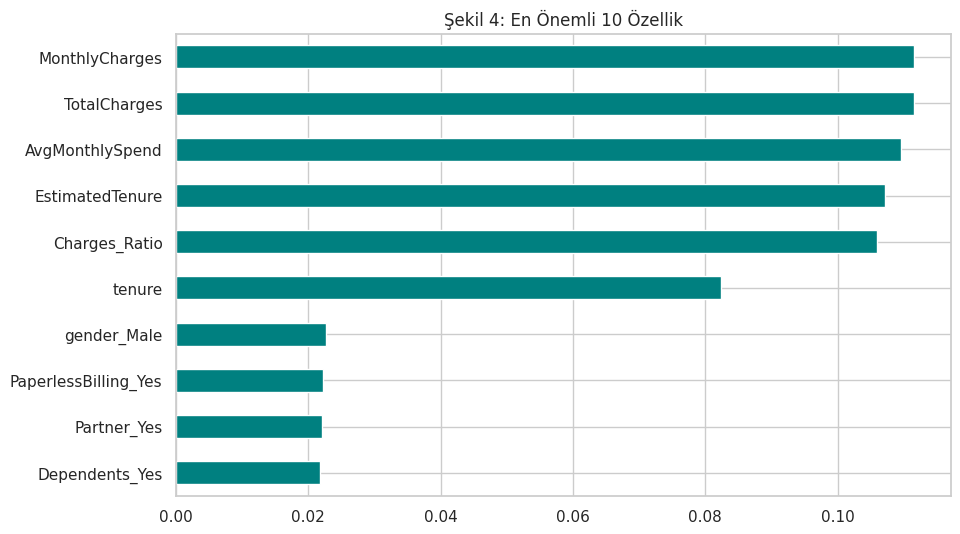

In [9]:
# Şekil 1: Karmaşıklık Matrisi
plt.figure(figsize=(6, 5))
sns.heatmap(confusion_matrix(y_test, best_model.predict(X_test)), annot=True, fmt='d', cmap='Blues')
plt.title('Şekil 1: Karmaşıklık Matrisi')
plt.show()

# Şekil 4: Özellik Önem Düzeyleri
plt.figure(figsize=(10, 6))
importances = best_model.named_steps['classifier'].feature_importances_
pd.Series(importances, index=X.columns).nlargest(10).sort_values().plot(kind='barh', color='teal')
plt.title('Şekil 4: En Önemli 10 Özellik')
plt.show()

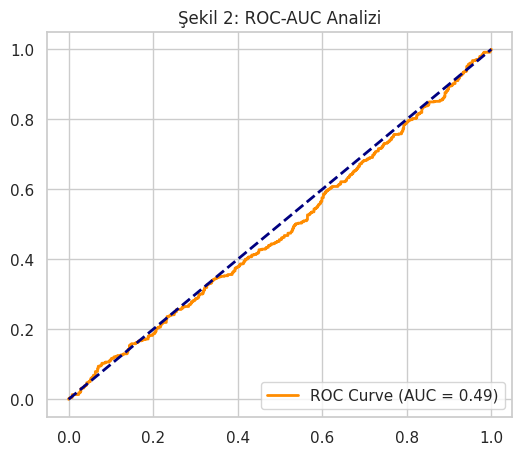

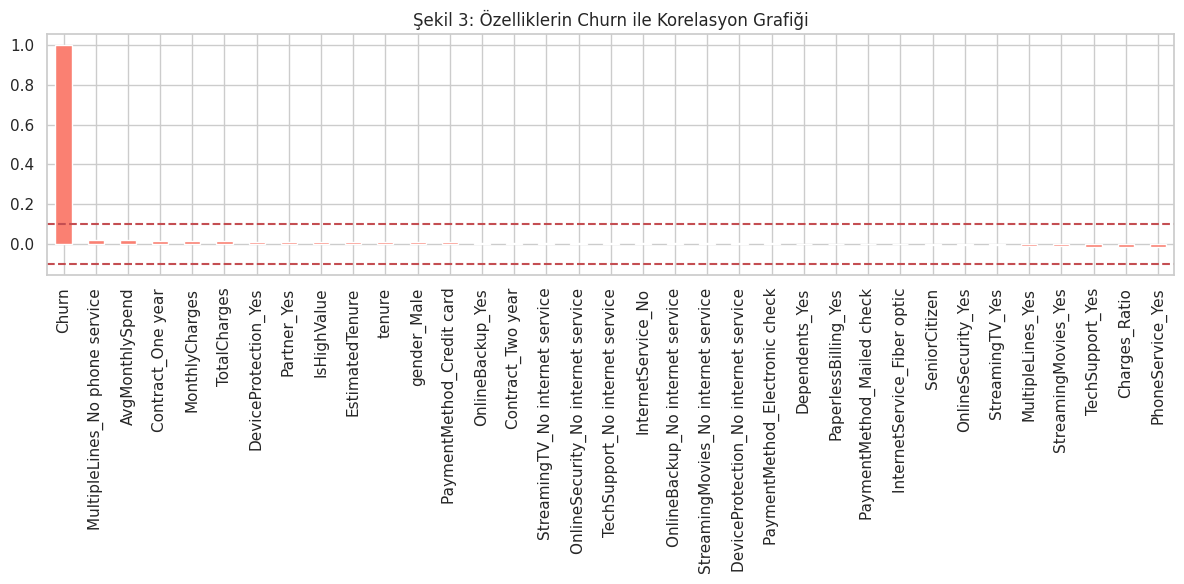

In [10]:
# Şekil 2: ROC-AUC Analizi
plt.figure(figsize=(6, 5))
fpr, tpr, _ = roc_curve(y_test, best_model.predict_proba(X_test)[:,1])
plt.plot(fpr, tpr, label=f'ROC Curve (AUC = {auc(fpr, tpr):.2f})', color='darkorange', lw=2)
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.title('Şekil 2: ROC-AUC Analizi')
plt.legend(loc="lower right")
plt.show()

# Şekil 3: Korelasyon Grafiği
plt.figure(figsize=(12, 6))
df.corr()['Churn'].sort_values(ascending=False).plot(kind='bar', color='salmon')
plt.title('Şekil 3: Özelliklerin Churn ile Korelasyon Grafiği')
plt.axhline(y=0.1, color='r', linestyle='--')
plt.axhline(y=-0.1, color='r', linestyle='--')
plt.tight_layout()
plt.show()

In [13]:
# 'Canlı Tahmin
# Test setinden rastgele 100. sıradaki müşteriyi alalım
yeni_musteri = X_test.iloc[100:101]

# Model
tahmin = xgb_pipe.predict(yeni_musteri)
olasilik = xgb_pipe.predict_proba(yeni_musteri)

print("--- MÜŞTERİ RİSK ANALİZİ ---")
print(f"Müşteri Durumu: {'⚠️ TERK EDEBİLİR (CHURN)' if tahmin[0] == 1 else '✅ SADIK MÜŞTERİ'}")
print(f"Terk Etme Olasılığı: %{olasilik[0][1]*100:.2f}")

--- MÜŞTERİ RİSK ANALİZİ ---
Müşteri Durumu: ✅ SADIK MÜŞTERİ
Terk Etme Olasılığı: %22.80
